## Recomendación: Sustitutos y casos

- **PQ3.1:** ¿hay proveedores técnicamente afines que diversifiquen la oferta de entidades cautivas y de procesos con postor único?

- Se leen casos concretos con los dos híbridos de `d_hibrido_evaluacion` y se verifica contra lo que realmente ocurrió en 2025

- **Encuadre:** una recomendación es un proveedor con **afinidad técnica** para un estudio de mercado previo a la convocatoria; no indica a quién contratar ni supone irregularidad en la contratación actual

### Constantes

- `N_CAUTIVAS`: entidades cautivas de mayor monto que se resumen

- `N_TERMINOS`: términos compartidos que explican una recomendación

- `MIN_OFERTAS_AFIN`: ofertas mínimas en train en la misma familia y región para contar a un proveedor como **afín** (descarta oferentes de una sola vez)

- `MIN_AFINES`: proveedores afines mínimos para considerar que un proceso con postor único tenía mercado

- `COMPETITIVOS`: métodos que convocan a competencia abierta; convenio, régimen especial, contratación internacional y estandarizados quedan fuera porque el postor único es frecuente **por diseño** (EDA: > 80% de postor único)

In [1]:
N_CAUTIVAS = 10
N_TERMINOS = 5
MIN_OFERTAS_AFIN = 3
MIN_AFINES = 5
COMPETITIVOS = r"LICITACI|CONCURSO|SUBASTA|ADJUDICACI.N SIMPLIFICADA|COMPARACI"

### Utilidades

In [2]:
NOTEBOOK = "e_analisis_sustitutos"
%run ../funciones.ipynb
%run funciones.ipynb

/opt/conda/lib/python3.11/site-packages/nbformat/__init__.py:93: MissingIDFieldWarning: Code cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
import joblib
from IPython.display import Markdown, display

config = leer_config(); WS = config["hibrido"]["w"]
c = contexto("final")
TRAIN, TEST = SPLITS["final"]["train"], SPLITS["final"]["test"]
cand = {v: pd.read_parquet(datos_dir / f"final_cand_{m}") for v, m in [("ponderado", "hibrido"), ("respaldo", "hibrido_respaldo")]}
union = pd.read_parquet(datos_dir / "final_union")
dim_p = leer(final_dir, "proveedores").select("proveedor_key", F.col("nombre").alias("proveedor")).toPandas().set_index("proveedor_key").proveedor
dim_e = leer(final_dir, "entidades").select("entidad_key", F.col("nombre").alias("entidad"), "region").toPandas().set_index("entidad_key")
modelo_cb = joblib.load(datos_dir / "final_contenido_modelo.joblib"); voc = np.array(modelo_cb["vec"].get_feature_names_out())
print("pesos:", WS)

pesos: {'ponderado': 0.7, 'respaldo': 1.0}


---
### **1. Explicación de una recomendación**

- **Origen:** si el proveedor vino del top-200 de ALS, del de contenido o de ambos

- **Términos compartidos:** los de mayor $x_{u,t} \cdot x_{i,t}$ entre el TF-IDF de los procesos de la entidad y el de los procesos en que ofertó el proveedor (train)

In [5]:
def documentos(ocids=None, entidad=None):
    p = leer(final_dir, "procesos").where(F.col("anio").isin(TRAIN))
    p = p.where(F.col("entidad_key") == entidad) if entidad else p.join(spark.createDataFrame(pd.DataFrame({"ocid": list(ocids)})), "ocid")
    return doc_procesos(p, TRAIN).doc.tolist()

def perfil(docs):
    return np.asarray(modelo_cb["vec"].transform(docs).mean(axis=0)).ravel() if docs else np.zeros(len(voc))

def terminos(entidad_key, proveedores):
    pe = perfil(documentos(entidad=entidad_key))
    part = (leer(final_dir, "participantes").where(F.col("anio").isin(TRAIN))
            .where(F.col("proveedor_key").isin(list(proveedores))).select("proveedor_key", "ocid").distinct().toPandas())
    out = {}
    for p in proveedores:
        pp = perfil(documentos(ocids=part.loc[part.proveedor_key == p, "ocid"]))
        x = pe * pp; top = np.argsort(-x)[:N_TERMINOS]
        out[p] = ", ".join(voc[top][x[top] > 0])
    return out

---
### **2. Caso: GR Loreto, Organismo de Infraestructura**

- En la Parte II fue la **entidad cautiva de mayor monto** (64% de su gasto a un consorcio), con el HHI calculado sobre **2023-2025**

- Aquí el HHI se mide solo en train (2023-2024): se verifica si la cautividad ya existía o apareció en el año de test

- Se busca por nombre; si no se encuentra, se toma la entidad cautiva de mayor monto en train

In [6]:
gasto = c.train.groupby("entidad_key").monto.sum()
ev = c.evaluables.set_index("entidad_key")
nom = dim_e.entidad.reindex(ev.index).fillna("")
loreto = nom[nom.str.contains("LORETO") & nom.str.contains("INFRAESTRUCTURA")]
CASO = loreto.index[0] if len(loreto) else gasto.reindex(ev.index[ev.cautiva == 1]).idxmax()
print(CASO, "|", dim_e.loc[CASO, "entidad"], "|", dim_e.loc[CASO, "region"], f"| HHI train {ev.loc[CASO, 'hhi_train']:.2f}")

ENT:200277 | GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTRUCTURA PARA LA PRODUCTIVIDAD | LORETO | HHI train 0.13


In [7]:
def proveedores_train(u):
    t = c.train[c.train.entidad_key == u].copy()
    t["pct_monto"] = t.monto / t.monto.sum()
    t["proveedor"] = t.proveedor_key.map(dim_p)
    return t.sort_values("monto", ascending=False)[["proveedor_key", "proveedor", "n_adj", "monto", "pct_monto"]]

def sustitutos(u, variante, k=10):
    t = cand[variante]; t = t[(t.regimen == "nuevos") & (t.entidad_key == u)].nsmallest(k, "rank").copy()
    o = union[(union.regimen == "nuevos") & (union.entidad_key == u)].set_index("proveedor_key").origen
    t["proveedor"] = t.proveedor_key.map(dim_p); t["origen"] = t.proveedor_key.map(o)
    t["nunca_gano"] = t.proveedor_key.isin(c.no_ganadores).astype(int)
    t["clientes_train"] = t.proveedor_key.map(c.popularidad).fillna(0).astype(int)
    t["adjudico_2025"] = t.proveedor_key.isin(c.verdad["nuevos"].get(u, set())).astype(int)
    return t

def reales_2025(u):
    r = c.test[(c.test.entidad_key == u) & (c.test.nuevo == 1)].copy()
    r["proveedor"] = r.proveedor_key.map(dim_p)
    for v in cand:
        rk = cand[v][(cand[v].regimen == "nuevos") & (cand[v].entidad_key == u)].set_index("proveedor_key")["rank"]
        r[f"rank_{v}"] = r.proveedor_key.map(rk)
    r["nunca_gano"] = r.proveedor_key.isin(c.no_ganadores).astype(int)
    r["desconocido"] = (~r.proveedor_key.isin(c.catalogo_keys)).astype(int)
    return r.sort_values("monto", ascending=False)

pt = proveedores_train(CASO)
print("Proveedores 2023-2024"); display(pt.head(8).round(3))

Proveedores 2023-2024


,proveedor_key,proveedor,n_adj,monto,pct_monto
45036,CONS:1493994,CONSORCIO SALUD CABALLOCOCHA,1,1.360000e+08,0.287
88675,CONS:1587778,CONSORCIO REASFALTADO DE IQUITOS,1,7.643323e+07,0.161
25968,CONS:1493228,CONSORCIO EJECUTOR PEDAGOGICO DE REQUENA,1,4.343417e+07,0.092
80259,CONS:590369,CONSORCIO ASOCIADOS JJ,1,3.250000e+07,0.069
52755,CONS:1545123,CONSORCIO ECOSISTEMAS LORETO,1,3.115465e+07,0.066
80007,RUC:20494740673,GAVILAN CONTRATISTAS GENERALES S.A.C.,1,2.531910e+07,0.053
17564,RUC:20393633990,CONSTRUCTORA PREIMAQ S.A.C.,2,2.199448e+07,0.046
13876,CONS:315586,CONSORCIO COLONIA,1,1.267650e+07,0.027


In [8]:
sus = {v: sustitutos(CASO, v) for v in cand}
term = terminos(CASO, set(sus["ponderado"].proveedor_key) | set(sus["respaldo"].proveedor_key))
for v, t in sus.items():
    t["terminos"] = t.proveedor_key.map(term)
    print(f"Sustitutos — híbrido {v} (w = {WS[v]:g})")
    display(t[["rank", "proveedor", "origen", "clientes_train", "nunca_gano", "adjudico_2025", "terminos"]])

Sustitutos — híbrido ponderado (w = 0.7)


,rank,proveedor,origen,clientes_train,nunca_gano,adjudico_2025,terminos
817200,1,MULTISERVICIOS Y CONSTRUCCIONES OSO E.I.R.L.,ambos,6,0,0,"loreto, maynas, contratacion, fam7212, iquitos"
817201,2,RIOS & LAGOS CORP. E.I.R.L.,ambos,6,0,0,"loreto, contratacion, obra, cui, supervision"
817202,3,JJR CONSTRUCTORA Y SERVICIOS GENERALES S.A.C.,ambos,4,0,0,"loreto, contratacion, obra, supervision, ejecucion"
817203,4,OCAÑA APONTE JUAN JESUS,ambos,5,0,0,"loreto, maynas, obra, cui, contratacion"
817204,5,CONSORCIO VILLALEVEAU S.R.L,ambos,2,0,0,"loreto, maynas, punchana, cui, ioarr"
817205,6,CONSTRUCTORA R & A INGENIEROS S.A.C.,ambos,6,0,0,"loreto, maynas, ejecucion, cui, obra"
817206,7,NVF BUSINESS GROUP S.A.C.,als,20,0,0,"contratacion, mejoramiento, cui, obra, ejecucion"
817207,8,SOLUCIONES EFICIENTES PERU E.I.R.L.,ambos,5,0,0,"loreto, maynas, obra, cui, contratacion"
817208,9,CONSTRUCTORA Y CONSULTORA COVERO E.I.R.L.,ambos,6,0,0,"loreto, contratacion, obra, cui, consultoria"
817209,10,INVERSIONES R. ORTIZ S.A.C.,als,12,0,0,"loreto, maynas, ucayali, contratacion, red"


Sustitutos — híbrido respaldo (w = 1)


,rank,proveedor,origen,clientes_train,nunca_gano,adjudico_2025,terminos
817200,1,BIENES & SERVICIOS GENERALES EMMA E.I.R.L.,als,3,0,0,"loreto, regional, contratacion, hospital, salud"
817201,2,ASUNCION SERVICIOS Y EDIFICACIONES SCRL,contenido,0,1,0,"loreto, maynas, cui, ejecucion, obra"
817202,3,INVERSIONES R. ORTIZ S.A.C.,als,12,0,0,"loreto, maynas, ucayali, contratacion, red"
817203,4,NVF BUSINESS GROUP S.A.C.,als,20,0,0,"contratacion, mejoramiento, cui, obra, ejecucion"
817204,5,MULTISERVICIOS Y CONSTRUCCIONES OSO E.I.R.L.,ambos,6,0,0,"loreto, maynas, contratacion, fam7212, iquitos"
817205,6,ICT GROUP S.A.C.,als,5,0,0,"maynas, provincial, contratacion, bienes, regional"
817206,7,JJR CONSTRUCTORA Y SERVICIOS GENERALES S.A.C.,ambos,4,0,0,"loreto, contratacion, obra, supervision, ejecucion"
817207,8,RIOS & LAGOS CORP. E.I.R.L.,ambos,6,0,0,"loreto, contratacion, obra, cui, supervision"
817208,9,ENTERCOM SOLUCIONES E.I.R.L.,als,2,0,0,"loreto, maynas, contratacion, bautista, belen"
817209,10,LA PERFECCION SINALOA EMPRESA INDIVIDUAL DE RESPONSABILIDAD LIMITADA,contenido,0,1,0,"loreto, maynas, contratacion, cui, ejecucion"


In [9]:
real = reales_2025(CASO)
print("Proveedores nuevos que le adjudicaron en 2025, y su posición en cada híbrido (top-200)")
display(real[["proveedor", "n_adj", "monto", "rank_ponderado", "rank_respaldo", "nunca_gano", "desconocido"]].head(10).round(0))

Proveedores nuevos que le adjudicaron en 2025, y su posición en cada híbrido (top-200)


,proveedor,n_adj,monto,rank_ponderado,rank_respaldo,nunca_gano,desconocido
21652,CONSORCIO SAN JUAN,1,989753525.0,NaN,NaN,0,1
33106,CONSORCIO SUPERVISOR HOSPITALARIO SELVA,1,59719427.0,NaN,NaN,0,1
48331,CONSORCIO HOSPITAL LORETO,1,22400610.0,NaN,NaN,0,1
33829,CONSORCIO CONSULTOR DIAMANTE,1,949796.0,NaN,NaN,0,1
32418,CONSORCIO SUPERVISOR LORETO,1,854817.0,NaN,NaN,0,1
15958,REPCONSERGE E.I.R.L.,2,273550.0,NaN,NaN,0,1
8253,INVERSIONES MILUSKA SOCIEDAD ANONIMA CERRADA,1,122815.0,NaN,NaN,1,0


In [10]:
top1 = pt.iloc[0]
s_p, s_r = sus["ponderado"], sus["respaldo"]
r25 = c.test[c.test.entidad_key == CASO].copy(); r25["pct"] = r25.monto / r25.monto.sum(); g25 = r25.nlargest(1, "monto").iloc[0]
hhi25 = float((r25.pct ** 2).sum()); hhi_tr = ev.loc[CASO, "hhi_train"]
display(Markdown(
    f"- **{dim_e.loc[CASO, 'entidad']}**: HHI **{hhi_tr:.2f}** en 2023-2024 y **{hhi25:.2f}** en 2025 "
    + (f"→ **no era cautiva antes**: la concentración aparece en 2025, cuando *{dim_p.get(g25.proveedor_key, g25.proveedor_key)}* "
       f"recibe el {g25.pct:.0%} del monto"
       + (" y es un proveedor **sin historia** en 2023-2024 (inalcanzable para cualquier modelo)\n" if g25.proveedor_key not in c.catalogo_keys else "\n")
       if hhi_tr < config["umbral_hhi"] <= hhi25 else "\n")
    + f"- En 2023-2024 su mayor proveedor fue *{top1.proveedor}* ({top1.pct_monto:.0%}); los 3 primeros sumaron {pt.pct_monto.head(3).sum():.0%}\n"
    f"- El híbrido ponderado propone 10 proveedores con una mediana de **{s_p.clientes_train.median():.0f} clientes** en train; "
    f"{int(s_p.adjudico_2025.sum())} le adjudicaron efectivamente en 2025\n"
    f"- El híbrido con respaldo propone **{int(s_r.nunca_gano.sum())} oferentes que nunca ganaron**; "
    f"{int(s_r.adjudico_2025.sum())} le adjudicaron en 2025\n"
    f"- En 2025 la entidad tuvo **{len(real)} proveedores nuevos**: {int(real.rank_ponderado.notna().sum())} estaban entre los 200 candidatos del ponderado, "
    f"{int(real.rank_respaldo.notna().sum())} entre los del respaldo y **{int(real.desconocido.sum())} no habían ofertado nunca** en 2023-2024 (inalcanzables)\n"
    "- Los términos compartidos mezclan **rubro** (obra, supervisión, familia UNSPSC) y **ubicación** (nombres de provincias y distritos): "
    "el contenido captura tanto el tipo de compra como el mercado local, porque ambos aparecen en la descripción de los procesos"))

- **GOBIERNO REGIONAL DE LORETO - ORGANISMO PUBLICO INFRAESTRUCTURA PARA LA PRODUCTIVIDAD**: HHI **0.13** en 2023-2024 y **0.85** en 2025 → **no era cautiva antes**: la concentración aparece en 2025, cuando *CONSORCIO SAN JUAN* recibe el 92% del monto y es un proveedor **sin historia** en 2023-2024 (inalcanzable para cualquier modelo)
- En 2023-2024 su mayor proveedor fue *CONSORCIO SALUD CABALLOCOCHA* (29%); los 3 primeros sumaron 54%
- El híbrido ponderado propone 10 proveedores con una mediana de **6 clientes** en train; 0 le adjudicaron efectivamente en 2025
- El híbrido con respaldo propone **2 oferentes que nunca ganaron**; 0 le adjudicaron en 2025
- En 2025 la entidad tuvo **7 proveedores nuevos**: 0 estaban entre los 200 candidatos del ponderado, 0 entre los del respaldo y **6 no habían ofertado nunca** en 2023-2024 (inalcanzables)
- Los términos compartidos mezclan **rubro** (obra, supervisión, familia UNSPSC) y **ubicación** (nombres de provincias y distritos): el contenido captura tanto el tipo de compra como el mercado local, porque ambos aparecen en la descripción de los procesos

---
### **3. Entidades cautivas de mayor monto**

Misma lectura, resumida, para las `N_CAUTIVAS` cautivas con más gasto en train

In [11]:
caut = gasto.reindex(ev.index[ev.cautiva == 1]).nlargest(N_CAUTIVAS).index
filas = []
for u in caut:
    p, r = proveedores_train(u), reales_2025(u)
    sp, sr = sustitutos(u, "ponderado"), sustitutos(u, "respaldo")
    filas.append({"entidad_key": u, "entidad": dim_e.entidad.get(u), "region": dim_e.region.get(u),
                  "monto_train_mm": gasto[u] / 1e6, "hhi_train": ev.loc[u, "hhi_train"], "pct_top1": p.pct_monto.iloc[0],
                  "proveedor_top1": p.proveedor.iloc[0], "nuevos_2025": len(r), "inalcanzables_2025": int(r.desconocido.sum()),
                  "aciertos10_ponderado": int(sp.adjudico_2025.sum()), "aciertos10_respaldo": int(sr.adjudico_2025.sum()),
                  "no_ganadores10_respaldo": int(sr.nunca_gano.sum()),
                  "en_top200_ponderado": int(r.rank_ponderado.notna().sum()), "en_top200_respaldo": int(r.rank_respaldo.notna().sum())})
cautivas = pd.DataFrame(filas)
cautivas.round(2)

,entidad_key,entidad,region,monto_train_mm,hhi_train,pct_top1,proveedor_top1,nuevos_2025,inalcanzables_2025,aciertos10_ponderado,aciertos10_respaldo,no_ganadores10_respaldo,en_top200_ponderado,en_top200_respaldo
0,ENT:2002,FONDO METROPOLITANO DE INVERSIONES,LIMA,1599.56,0.30,0.42,CONSORCIO HUAYLAS,63,41,0,0,8,8,3
1,ENT:10369,GOBIERNO REGIONAL DE ICA - PROYECTO ESPECIAL TAMBO CCARACOCHA,ICA,688.43,0.35,0.58,CONSORCIO HIDRAULICO LOROS,3,1,0,0,3,0,0
2,ENT:10449,GOBIERNO REGIONAL DE CUSCO - DIRECCION REGIONAL DE TRANSPORTES Y COMUNICACIO...,CUSCO,498.20,0.26,0.49,CONSORCIO CYMSOCOIRH,83,48,1,1,3,5,4
3,ENT:201225,UNIDAD EJECUTORA 032: DIRECCION GENERAL DE INFRAESTRUCTURA,LIMA,437.19,0.41,0.63,CONSORCIO PACIFICO,17,6,0,0,1,1,0
4,ENT:204387,PROGRAMA NACIONAL DE TELECOMUNICACIONES,LIMA,410.43,0.27,0.40,VIETTEL PERU S.A.C.,35,23,1,1,4,2,4
5,ENT:2391,EMPRESA DE ELECTRICIDAD DEL PERÚ S.A. - ELECTROPERU,LIMA,385.65,0.50,0.70,CONSORCIO GE HYDRO,28,6,0,0,0,4,4
6,ENT:10143,DIRECCION DE ECONOMIA Y FINANZAS DE LA POLICIA NACIONAL DEL PERU - PNP,LIMA,346.02,0.35,0.58,VIETTEL PERU S.A.C.,37,13,0,0,0,5,5
7,ENT:1922,"SUPERINTENDENCIA DE BANCA, SEGUROS Y AFP",LIMA,304.31,0.39,0.62,CONSORCIO OHLA - HV,55,34,2,0,3,8,7
8,ENT:1341,MUNICIPALIDAD DISTRITAL DE SAN MARTIN DE PORRES,LIMA,262.05,0.31,0.55,REPRESENTACIONES PERUANAS DEL SUR S.A.,49,25,1,0,9,9,7
9,ENT:1852,MUNICIPALIDAD DISTRITAL DE ILABAYA,TACNA,194.92,0.29,0.53,GENUS SVC S.A.C.,73,40,0,1,0,12,12


In [12]:
tot = cautivas[["nuevos_2025", "inalcanzables_2025", "en_top200_ponderado", "en_top200_respaldo", "aciertos10_ponderado", "aciertos10_respaldo"]].sum()
display(Markdown(
    f"- Las {N_CAUTIVAS} cautivas de mayor monto concentraron en promedio el **{cautivas.pct_top1.mean():.0%}** de su gasto en un proveedor\n"
    f"- En 2025 sumaron **{int(tot.nuevos_2025)} proveedores nuevos**: {int(tot.inalcanzables_2025)} sin historia de ofertas (inalcanzables), "
    f"{int(tot.en_top200_ponderado)} entre los candidatos del ponderado y {int(tot.en_top200_respaldo)} del respaldo\n"
    f"- En el top-10: {int(tot.aciertos10_ponderado)} aciertos del ponderado y {int(tot.aciertos10_respaldo)} del respaldo\n"
    "- Sí existen sustitutos observables: parte de los proveedores que las cautivas incorporaron en 2025 ya estaba en su lista de afines"))

- Las 10 cautivas de mayor monto concentraron en promedio el **55%** de su gasto en un proveedor
- En 2025 sumaron **443 proveedores nuevos**: 237 sin historia de ofertas (inalcanzables), 54 entre los candidatos del ponderado y 46 del respaldo
- En el top-10: 5 aciertos del ponderado y 3 del respaldo
- Sí existen sustitutos observables: parte de los proveedores que las cautivas incorporaron en 2025 ya estaba en su lista de afines

---
### **4. Procesos con postor único en 2025**

- Un proceso con postor único no es irregular por sí mismo: la contratación directa lo es por diseño

- Se separan los métodos **competitivos** (`COMPETITIVOS`) de los que tienen postor único por diseño, y se pregunta: ¿cuántos proveedores **afines** existían, es decir, con al menos `MIN_OFERTAS_AFIN` ofertas en 2023-2024 en la **misma familia UNSPSC y región**, sin contar al ganador?

- Si había un mercado de proveedores afines y solo se presentó uno, la difusión o los requisitos de la convocatoria merecen revisión

In [13]:
pu = (leer(final_dir, "procesos").where(F.col("anio").isin(TEST) & (F.col("postor_unico") == 1))
      .select("ocid", "entidad_key", "region", "metodo_detalle", "es_directa", "monto_referencial"))
fam25 = (leer(final_dir, "hechos").where(F.col("anio").isin(TEST) & (F.col("familia") != "SIN"))
         .select("ocid", "familia", "proveedor_key").distinct())
fam_tr = (leer(final_dir, "hechos").where(F.col("anio").isin(TRAIN) & (F.col("familia") != "SIN")).select("ocid", "familia").distinct()
          .join(leer(final_dir, "procesos").where(F.col("anio").isin(TRAIN)).select("ocid", "region"), "ocid"))
oferta = (leer(final_dir, "participantes").where(F.col("anio").isin(TRAIN)).select("ocid", "proveedor_key").distinct()
          .join(fam_tr, "ocid").groupBy("proveedor_key", "familia", "region").agg(F.countDistinct("ocid").alias("n_ofertas")).cache())
afin = oferta.where(F.col("n_ofertas") >= MIN_OFERTAS_AFIN)
af_f = afin.groupBy("familia").agg(F.countDistinct("proveedor_key").alias("afines_familia"))
af_fr = afin.groupBy("familia", "region").agg(F.countDistinct("proveedor_key").alias("afines_familia_region"))
ganador_previo = oferta.select("proveedor_key", "familia").distinct().withColumn("ganador_oferto_antes", F.lit(1))
ganador_afin = afin.select("proveedor_key", "familia", "region").withColumn("ganador_afin", F.lit(1))

pu_f = (pu.join(fam25, "ocid").join(af_f, "familia", "left").join(af_fr, ["familia", "region"], "left")
          .join(ganador_previo, ["proveedor_key", "familia"], "left").join(ganador_afin, ["proveedor_key", "familia", "region"], "left")
          .fillna(0, ["afines_familia", "afines_familia_region", "ganador_oferto_antes", "ganador_afin"])
          .withColumn("afines_familia_region", F.col("afines_familia_region") - F.col("ganador_afin"))
          .groupBy("ocid", "entidad_key", "region", "metodo_detalle", "es_directa", "monto_referencial", "proveedor_key")
          .agg(F.max("afines_familia").alias("afines_familia"), F.max("afines_familia_region").alias("afines_familia_region"),
               F.max("ganador_oferto_antes").alias("ganador_oferto_antes"), F.first("familia").alias("familia"))).toPandas()
print(f"procesos con postor único en {TEST[0]} con familia: {pu_f.ocid.nunique():,}")
pu_f.groupby("metodo_detalle").ocid.nunique().sort_values(ascending=False).head(12)

procesos con postor único en 2025 con familia: 7,483


metodo_detalle
CONTRATACIÓN DIRECTA             3252
REGÍMEN ESPECIAL                 1497
CONTRATACIÓN INTERNACIONAL       1049
CONVENIO                          830
ADJUDICACIÓN ABREVIADA            420
ADJUDICACIÓN SIMPLIFICADA         133
CONCURSO PÚBLICO ABREVIADO        125
LICITACIÓN PÚBLICA ABREVIADA      107
ADJUDICACIÓN SELECTIVA             27
COMPARACIÓN DE PRECIOS             12
LICITACIÓN PÚBLICA                 12
CONCURSO PÚBLICO DE SERVICIOS       7
Name: ocid, dtype: int64

In [14]:
pu_f["tipo"] = np.select([pu_f.es_directa == 1, pu_f.metodo_detalle.fillna("").str.contains(COMPETITIVOS, regex=True)],
                         ["contratación directa", "competitivo"], "no competitivo por diseño")
pu_f["con_mercado"] = (pu_f.afines_familia_region >= MIN_AFINES).astype(int)
resumen_pu = pu_f.groupby("tipo").agg(procesos=("ocid", "nunique"),
                                      afines_familia_mediana=("afines_familia", "median"),
                                      afines_region_mediana=("afines_familia_region", "median"),
                                      pct_con_mercado=("con_mercado", "mean"),
                                      pct_ganador_oferto_antes=("ganador_oferto_antes", "mean"),
                                      monto_mm=("monto_referencial", lambda x: x.sum() / 1e6)).round(3)
resumen_pu

,procesos,afines_familia_mediana,afines_region_mediana,pct_con_mercado,pct_ganador_oferto_antes,monto_mm
tipo,,,,,,
competitivo,405,253.0,48.0,0.818,0.656,187.168
contratación directa,3252,212.0,57.0,0.791,0.539,4661.600
no competitivo por diseño,3826,214.0,157.0,0.941,0.433,3816.422


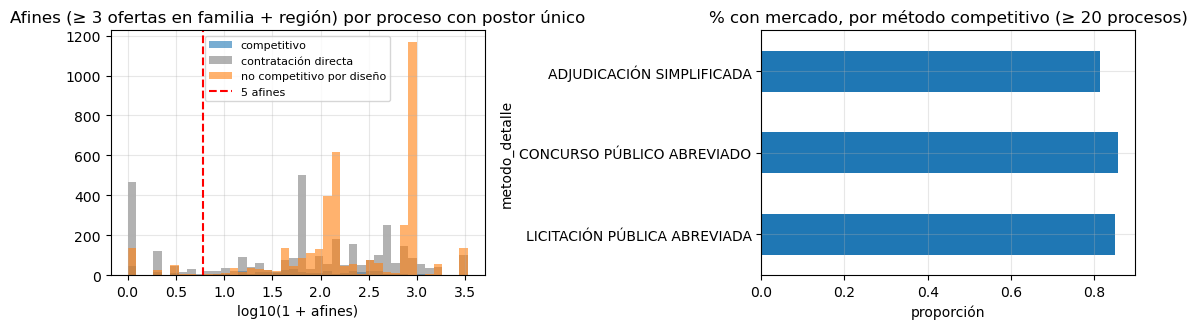

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for t, col in [("competitivo", "tab:blue"), ("contratación directa", "tab:gray"), ("no competitivo por diseño", "tab:orange")]:
    x = pu_f.loc[pu_f.tipo == t, "afines_familia_region"]
    ax[0].hist(np.log10(1 + x), bins=40, alpha=.6, color=col, label=t)
ax[0].axvline(np.log10(1 + MIN_AFINES), color="red", ls="--", label=f"{MIN_AFINES} afines")
ax[0].set(title=f"Afines (≥ {MIN_OFERTAS_AFIN} ofertas en familia + región) por proceso con postor único", xlabel="log10(1 + afines)"); ax[0].legend(fontsize=8)
m = pu_f[pu_f.tipo == "competitivo"].groupby("metodo_detalle").agg(n=("ocid", "nunique"), con_mercado=("con_mercado", "mean"))
m[m.n >= 20].sort_values("n").con_mercado.plot.barh(ax=ax[1], color="tab:blue")
ax[1].set(title="% con mercado, por método competitivo (≥ 20 procesos)", xlabel="proporción")
mostrar_fig("postor_unico_mercado")

In [16]:
casos_pu = (pu_f[(pu_f.tipo == "competitivo") & (pu_f.con_mercado == 1)].sort_values("monto_referencial", ascending=False)
            .drop_duplicates("ocid").head(10).copy())
casos_pu["entidad"] = casos_pu.entidad_key.map(dim_e.entidad); casos_pu["ganador"] = casos_pu.proveedor_key.map(dim_p)
casos_pu[["ocid", "entidad", "region", "metodo_detalle", "familia", "monto_referencial", "afines_familia_region", "ganador", "ganador_oferto_antes"]]

,ocid,entidad,region,metodo_detalle,familia,monto_referencial,afines_familia_region,ganador,ganador_oferto_antes
7334,ocds-dgv273-seacev3-2025-200489-9,FONDO INTANGIBLE SOLIDARIO DE SALUD,LIMA,ADJUDICACIÓN SIMPLIFICADA-HOMOLOGACIÓN,8512,18813880.80,121,CENTRO RENAL SAN MARTÍN S.A.C.,1
2470,ocds-dgv273-seacev3-1135612,FONDO INTANGIBLE SOLIDARIO DE SALUD,LIMA,ADJUDICACIÓN SIMPLIFICADA-HOMOLOGACIÓN,8512,13408059.60,120,CENTROMED DE LA HUMANIDAD S.A.C,1
5258,ocds-dgv273-seacev3-1178849,FONDO INTANGIBLE SOLIDARIO DE SALUD,LIMA,CONCURSO PÚBLICO ABREVIADO HOMOLOGACIÓN,8512,10707325.20,120,CENTRO NEFROLOGICO SANTA LUCIA S.A.C.,1
7428,ocds-dgv273-seacev3-2025-2543-1309,SEGURO SOCIAL DE SALUD,LIMA,ADJUDICACIÓN SIMPLIFICADA-HOMOLOGACIÓN,8512,9877120.00,121,CONSORCIO DE HEMODIÁLISIS CUSCO,0
5953,ocds-dgv273-seacev3-2025-1312-16,MUNICIPALIDAD DISTRITAL DE CARABAYLLO,LIMA,CONCURSO PÚBLICO DE SERVICIOS,7212,5740845.00,3347,PETRAMAS S.A.C.,1
5015,ocds-dgv273-seacev3-1175655,MUNICIPALIDAD DISTRITAL DE SAN JUAN BAUTISTA - LORETO,LORETO,LICITACIÓN PÚBLICA ABREVIADA,7214,4993885.39,247,CONSORCIO JESSICA III,0
1043,ocds-dgv273-seacev3-1111369,FONDO INTANGIBLE SOLIDARIO DE SALUD,LIMA,ADJUDICACIÓN SIMPLIFICADA-HOMOLOGACIÓN,8512,4627303.20,121,CONSORCIO RENAL PIURA,0
5875,ocds-dgv273-seacev3-2025-10198-50,INSTITUTO NACIONAL DE SALUD DEL NIÑO,LIMA,LICITACIÓN PÚBLICA,1214,4039200.00,10,LINDE PERU S.R.L.,1
7364,ocds-dgv273-seacev3-2025-21-45,MINISTERIO DE RELACIONES EXTERIORES,LIMA,ADJUDICACIÓN SIMPLIFICADA,7810,3529052.12,308,DHL EXPRESS PERÚ S.A.C.,1
4285,ocds-dgv273-seacev3-1163375,"SUPERINTENDENCIA DE BANCA, SEGUROS Y AFP",LIMA,ADJUDICACIÓN SIMPLIFICADA,8011,3248800.00,148,MANPOWER PERU S.A.,1


In [17]:
r = resumen_pu.loc["competitivo"]
otros = resumen_pu.drop(index="competitivo").procesos.sum()
cuartiles = pu_f[pu_f.tipo == "competitivo"].drop_duplicates("ocid").afines_familia_region.quantile([.25, .5, .75])
display(Markdown(
    f"- **{int(r.procesos):,} procesos competitivos** terminaron con postor único en {TEST[0]} (S/{r.monto_mm:,.0f} M referenciales); "
    f"otros {int(otros):,} usan métodos donde el postor único es frecuente por diseño\n"
    f"- Proveedores afines por proceso competitivo (≥ {MIN_OFERTAS_AFIN} ofertas previas en la misma familia y región, sin el ganador): "
    f"cuartiles {cuartiles.iloc[0]:.0f} / **{cuartiles.iloc[1]:.0f}** / {cuartiles.iloc[2]:.0f}; "
    f"**{r.pct_con_mercado:.0%}** tenía al menos {MIN_AFINES}\n"
    f"- En el {r.pct_ganador_oferto_antes:.0%} de los casos el único postor ya ofertaba en esa familia\n"
    "- **Lectura:** donde había varios proveedores afines activos y se presentó uno solo, conviene revisar difusión, plazos y requisitos "
    "de la convocatoria; donde no los había, el postor único refleja un mercado delgado"))

- **405 procesos competitivos** terminaron con postor único en 2025 (S/187 M referenciales); otros 7,078 usan métodos donde el postor único es frecuente por diseño
- Proveedores afines por proceso competitivo (≥ 3 ofertas previas en la misma familia y región, sin el ganador): cuartiles 14 / **48** / 197; **82%** tenía al menos 5
- En el 66% de los casos el único postor ya ofertaba en esa familia
- **Lectura:** donde había varios proveedores afines activos y se presentó uno solo, conviene revisar difusión, plazos y requisitos de la convocatoria; donde no los había, el postor único refleja un mercado delgado

---
### **5. Origen de las recomendaciones**

¿De qué modelo vienen los top-10 de cada híbrido (pares nuevos, 2025)?

In [18]:
orig = []
for v, t in cand.items():
    x = t[(t.regimen == "nuevos") & (t["rank"] <= 10)].merge(union[union.regimen == "nuevos"][["entidad_key", "proveedor_key", "origen"]],
                                                             on=["entidad_key", "proveedor_key"], how="left")
    x["acierto"] = [int(p in c.verdad["nuevos"].get(u, ())) for u, p in zip(x.entidad_key, x.proveedor_key)]
    orig.append(x.groupby("origen").agg(recomendaciones=("acierto", "size"), aciertos=("acierto", "sum"))
                 .assign(variante=v, precision=lambda d: d.aciertos / d.recomendaciones).reset_index())
orig = pd.concat(orig)[["variante", "origen", "recomendaciones", "aciertos", "precision"]].round(4)
orig

,variante,origen,recomendaciones,aciertos,precision
0,ponderado,als,13931,486,0.0349
1,ponderado,ambos,12411,609,0.0491
2,ponderado,contenido,378,4,0.0106
0,respaldo,als,10762,449,0.0417
1,respaldo,ambos,3344,279,0.0834
2,respaldo,contenido,12614,80,0.0063


---
### **6. Síntesis de la Parte III**

In [19]:
ev_d = pd.read_parquet(Path.cwd() / "temp" / "d_hibrido_evaluacion" / "tablas" / "evaluacion_final")
ic_d = pd.read_parquet(Path.cwd() / "temp" / "d_hibrido_evaluacion" / "tablas" / "ic_vs_als").set_index(["regimen", "comparacion"])
lim = pd.read_parquet(Path.cwd() / "temp" / "a_preparacion_split" / "tablas" / "limites_cold_start").set_index(["split", "pares_test"])
q = ev_d[(ev_d.regimen == "nuevos") & (ev_d.grupo == "todas") & (ev_d.universo == "completo") & (ev_d.k == 10)].set_index("modelo")
qc = ev_d[(ev_d.regimen == "nuevos") & (ev_d.grupo == "cautivas") & (ev_d.universo == "completo") & (ev_d.k == 10)].set_index("modelo")
l = lim.loc[("final", "nuevos")]; ih = ic_d.loc[("nuevos", "hibrido − als")]; ir = ic_d.loc[("nuevos", "hibrido_respaldo − als")]
display(Markdown(f'''
**PQ3.1 — Sustitutos para entidades cautivas y postor único**

- En entidades cautivas, el híbrido ponderado recupera sustitutos reales de 2025 con NDCG@10 = **{qc.loc['hibrido', 'ndcg']:.3f}** (ALS {qc.loc['als', 'ndcg']:.3f}; popularidad {qc.loc['popularidad_global', 'ndcg']:.3f})
- En los procesos competitivos con postor único, el **{r.pct_con_mercado:.0%}** tenía al menos {MIN_AFINES} proveedores afines activos (≥ {MIN_OFERTAS_AFIN} ofertas) en su familia y región
- En las {N_CAUTIVAS} cautivas de mayor monto, {int(tot.en_top200_ponderado)} de sus {int(tot.nuevos_2025)} proveedores nuevos de 2025 estaban entre los candidatos del híbrido, y {int(tot.inalcanzables_2025)} no tenían historia
- **Respuesta:** sí, en parte; los sustitutos se pueden identificar con la historia de ofertas, pero el acierto exacto es bajo y una fracción grande de los proveedores que efectivamente entran es nueva en el mercado (el caso de GR Loreto en 2025 es de ese tipo)

**PQ3.2 — Cola larga, *cold-start* y sesgo de popularidad**

- El **{l.pares / lim.loc[('final', 'todos'), 'pares']:.0%}** de los pares de 2025 son nuevos y el **{1 - l.pct_alcanzable_contenido:.0%}** de ellos va a proveedores sin historia: ningún modelo los alcanza
- ALS es el modelo base más fuerte (NDCG@10 {q.loc['als', 'ndcg']:.3f}) pero **nunca recomienda a quien no ganó**
- **Híbrido ponderado** (w = {WS['ponderado']:g}): {q.loc['hibrido', 'ndcg']:.3f}, mejora significativa sobre ALS ({ih.media:+.4f}, IC [{ih.ic_inf:+.4f}, {ih.ic_sup:+.4f}]) y baja la popularidad media de {q.loc['als', 'popularidad_media']:.0f} a {q.loc['hibrido', 'popularidad_media']:.0f} clientes; 0% no ganadores
- **Híbrido con respaldo** (w = {WS['respaldo']:g}): **{q.loc['hibrido_respaldo', 'pct_no_ganadores']:.0%} de no ganadores** recomendados a cambio de {ir.media:+.4f} de NDCG frente a ALS
- **Respuesta:** el híbrido supera el sesgo de popularidad solo parcialmente; descubrir oferentes que nunca ganaron tiene un costo medible en acierto, y la frontera entre ambos objetivos es una decisión de uso, no técnica
'''))


**PQ3.1 — Sustitutos para entidades cautivas y postor único**

- En entidades cautivas, el híbrido ponderado recupera sustitutos reales de 2025 con NDCG@10 = **0.046** (ALS 0.042; popularidad 0.014)
- En los procesos competitivos con postor único, el **82%** tenía al menos 5 proveedores afines activos (≥ 3 ofertas) en su familia y región
- En las 10 cautivas de mayor monto, 54 de sus 443 proveedores nuevos de 2025 estaban entre los candidatos del híbrido, y 237 no tenían historia
- **Respuesta:** sí, en parte; los sustitutos se pueden identificar con la historia de ofertas, pero el acierto exacto es bajo y una fracción grande de los proveedores que efectivamente entran es nueva en el mercado (el caso de GR Loreto en 2025 es de ese tipo)

**PQ3.2 — Cola larga, *cold-start* y sesgo de popularidad**

- El **75%** de los pares de 2025 son nuevos y el **54%** de ellos va a proveedores sin historia: ningún modelo los alcanza
- ALS es el modelo base más fuerte (NDCG@10 0.056) pero **nunca recomienda a quien no ganó**
- **Híbrido ponderado** (w = 0.7): 0.060, mejora significativa sobre ALS (+0.0036, IC [+0.0014, +0.0056]) y baja la popularidad media de 26 a 22 clientes; 0% no ganadores
- **Híbrido con respaldo** (w = 1): **47% de no ganadores** recomendados a cambio de -0.0100 de NDCG frente a ALS
- **Respuesta:** el híbrido supera el sesgo de popularidad solo parcialmente; descubrir oferentes que nunca ganaron tiene un costo medible en acierto, y la frontera entre ambos objetivos es una decisión de uso, no técnica


### **7. Limitaciones y ética**

- **Señal, no prescripción:** una recomendación indica afinidad técnica observada en ofertas pasadas; no evalúa capacidad, solvencia ni idoneidad legal del proveedor

- **Adjudicación ≠ calidad:** el modelo aprende de quién ganó, no de quién cumplió bien; reproduce los sesgos del sistema de compras

- **Consorcios sin miembros:** el consorcio es un nodo propio; una empresa que participa solo en consorcios aparece fragmentada

- ***Cold-start*:** más de la mitad de los pares nuevos van a proveedores sin historia; ningún modelo basado en el pasado los puede anticipar

- **Postor único:** contar proveedores afines no prueba que hubo restricción de competencia; puede haber requisitos técnicos legítimos, plazos o montos que expliquen la baja participación

- **Uso previsto:** apoyo al estudio de mercado y a la difusión de convocatorias por parte de la entidad o del órgano supervisor; no para descalificar proveedores ni para direccionar contrataciones

---
### **8. Artefactos para la app web**

En `temp/artefactos_web/`: casos de cautivas y resumen de postor único

In [20]:
web = Path.cwd() / "temp" / "artefactos_web"; web.mkdir(parents=True, exist_ok=True)
cautivas.to_parquet(web / "cautivas_casos.parquet", index=False)
pd.concat([t.assign(variante=v, entidad_key=CASO) for v, t in sus.items()]).to_parquet(web / "caso_loreto_sustitutos.parquet", index=False)
pu_f.drop_duplicates("ocid")[["ocid", "entidad_key", "region", "tipo", "metodo_detalle", "familia", "monto_referencial",
                              "afines_familia", "afines_familia_region", "con_mercado", "ganador_oferto_antes"]] \
    .to_parquet(web / "postor_unico_2025.parquet", index=False)
pd.DataFrame([{"archivo": p.name, "mb": round(p.stat().st_size / 1024**2, 2)} for p in sorted(web.glob("*.parquet"))])

,archivo,mb
0,caso_loreto_sustitutos.parquet,0.01
1,cautivas_casos.parquet,0.01
2,curva_w.parquet,0.01
3,entidades.parquet,0.10
4,factores_2d.parquet,0.11
5,metricas_modelos.parquet,0.01
6,postor_unico_2025.parquet,0.14
7,recomendaciones.parquet,8.25


### **9. Escritura de resultados**

In [21]:
escritos = guardar_tablas({"caso_proveedores_train": pt, "caso_sustitutos": pd.concat([t.assign(variante=v) for v, t in sus.items()]),
                           "caso_reales_2025": real, "cautivas": cautivas, "postor_unico_resumen": resumen_pu.reset_index(),
                           "postor_unico_casos": casos_pu, "origen_recomendaciones": orig})

Escrito en 03_Recomendacion/temp/e_analisis_sustitutos/: caso_proveedores_train, caso_sustitutos, caso_reales_2025, cautivas, postor_unico_resumen, postor_unico_casos, origen_recomendaciones


#### a. Verificación

In [22]:
verificar_salidas(escritos)
assert len(cautivas) == N_CAUTIVAS and (cautivas.hhi_train >= config["umbral_hhi"]).all()
assert all(len(t) <= 10 for t in sus.values())

OK: 7 tablas (parquet + json) | 1 figuras: postor_unico_mercado


---
### **10. Cerrar sesión**

In [23]:
spark.stop()